# 04 – Backtest, benchmarks and performance

A hypothetical backtest of the **current** weights from 2019 onwards, compared with the main benchmark (50% MSCI World / 35% Bloomberg Commodity / 15% MSCI EM IMI) and the look-through benchmark per pie, followed by a reconciliation with the Archief sheet of the workbook.

**Read this first.** Everything before 31-10-2026 is a backtest of today's selection. It contains hindsight (look-ahead and selection bias): the positions were chosen knowing how the world turned out. The results describe how this portfolio *would have behaved*, not how well it was *managed*.

**Methodological choices**
- Returns: daily total returns in EUR (Yahoo `Adj Close`, ECB rates), proxies before fund launch as documented in notebook 02.
- Positions without data yet: their weight is redistributed pro rata **within the same pie**, so pie weights (27/13/10/18/17/15) and the 50/50 block split stay intact.
- Two strategies: **monthly rebalanced** to target weights, and **buy-and-hold**. Both also rebalance on the few days when a new position enters the data (the investable universe changes).
- Risk-free rate: €STR (ECB). Before its launch (October 2019) the first €STR value is used.
- Sub-periods: 2019–2021, 2022 (rate shock), 2023–now.

## Setup

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from portfolio_analysis.backtest import backtest, month_ends, universe_changes
from portfolio_analysis.config import TRADING_DAYS
from portfolio_analysis.performance import metrics

In [2]:
PROCESSED_DIR = Path("../data/processed")
DATA_PATH = Path("../data/raw/portfolio_20261031.xlsx")
DB_PATH = PROCESSED_DIR / "portfolio.db"

HICP_URL = (
    "https://data-api.ecb.europa.eu/service/data/ICP/M.U2.N.000000.4.INX"
    "?format=csvdata&startPeriod=2018-12"
)
ESTR_URL = (
    "https://data-api.ecb.europa.eu/service/data/EST/B.EU000A2X2A25.WT"
    "?format=csvdata&startPeriod=2019-01-01"
)

MAIN_BENCHMARK = {"IWDA": 0.50, "CMOD": 0.35, "EIMI": 0.15}
PIE_BENCHMARKS = {
    "Kwaliteit": {"IWQU": 1.0},
    "Thematisch": {"IWDA": 1.0},
    "AI Boom": {"AIQU": 1.0},
    "Energie": {"WNRG": 0.70, "NUCL": 0.30},
    "Mijnbouw": {"GDX": 0.65, "COPX": 0.35},
    "Multipolaire Wereldorde": {"EIMI": 1.0},
}
SUBPERIODS = {
    "2019-2021": ("2019-01-01", "2021-12-31"),
    "2022": ("2022-01-01", "2022-12-31"),
    "2023-now": ("2023-01-01", "2100-01-01"),
}

## Load data

In [3]:
holdings = pd.read_parquet(PROCESSED_DIR / "holdings.parquet")
returns_total = pd.read_parquet(PROCESSED_DIR / "returns_total_eur.parquet")
returns_price = pd.read_parquet(PROCESSED_DIR / "returns_price_eur.parquet")

target = holdings.set_index("ticker")["weight_in_portfolio"]
pie_of = holdings.set_index("ticker")["pie"]

missing = set(target.index) - set(returns_total.columns)
assert not missing, f"No returns for: {missing}"
print(returns_total.shape)
returns_total.index.min(), returns_total.index.max()

(2027, 63)


(Timestamp('2019-01-02 00:00:00'), Timestamp('2026-11-03 00:00:00'))

## Risk-free rate (€STR)

€STR is an annualised overnight rate in percent, act/360. The daily risk-free return between two trading days is the rate times the number of calendar days in between, divided by 360.

In [4]:
estr_raw = pd.read_csv(ESTR_URL)
estr = estr_raw.set_index(pd.to_datetime(estr_raw["TIME_PERIOD"]))["OBS_VALUE"].sort_index()

dates = returns_total.index
estr_daily = estr.reindex(dates.union(estr.index)).ffill().bfill().reindex(dates)
calendar_days = dates.to_series().diff().dt.days.fillna(1)
rf = estr_daily / 100 * calendar_days / 360

print(f"€STR from {estr.index.min().date()}, last value {estr.iloc[-1]:.3f}%")
rf.resample("YE").sum().round(4)

€STR from 2019-10-01, last value 2.441%


Date
2019-12-31   -0.0055
2020-12-31   -0.0056
2021-12-31   -0.0058
2022-12-31   -0.0001
2023-12-31    0.0324
2024-12-31    0.0373
2025-12-31    0.0221
2026-12-31    0.0178
Freq: YE-DEC, dtype: float64

## Backtest engine

The engine lives in `portfolio_analysis.backtest` and is covered by unit tests. `rebalance_weights` sets target weights, redistributing the weight of positions without data within their group (pie). `backtest` lets weights drift with returns between rebalance dates. Weights set at the close of day *t* apply to the returns of day *t+1*, so no return is used before it is known.

## Portfolio and benchmark returns

In [5]:
holding_returns = returns_total[target.index]
new_data_dates = universe_changes(holding_returns)
print(f"Universe changes on {len(new_data_dates)} dates:", [d.date() for d in new_data_dates])

port_monthly = backtest(holding_returns, target, pie_of, month_ends(dates) + new_data_dates)
port_buy_hold = backtest(holding_returns, target, pie_of, new_data_dates)

bench_target = pd.Series(MAIN_BENCHMARK)
bench_groups = pd.Series("benchmark", index=bench_target.index)
bench_monthly = backtest(returns_total, bench_target, bench_groups, month_ends(dates))

series = pd.DataFrame({
    "Portfolio (monthly rebalanced)": port_monthly,
    "Portfolio (buy-and-hold)": port_buy_hold,
    "Main benchmark (monthly)": bench_monthly,
    "MSCI World (IWDA)": returns_total["IWDA"],
})
series.dropna().shape

Universe changes on 10 dates: [datetime.date(2019, 1, 3), datetime.date(2019, 1, 4), datetime.date(2019, 4, 11), datetime.date(2019, 6, 21), datetime.date(2019, 9, 25), datetime.date(2021, 5, 7), datetime.date(2022, 1, 20), datetime.date(2024, 3, 28), datetime.date(2024, 4, 26), datetime.date(2025, 9, 8)]


(2025, 4)

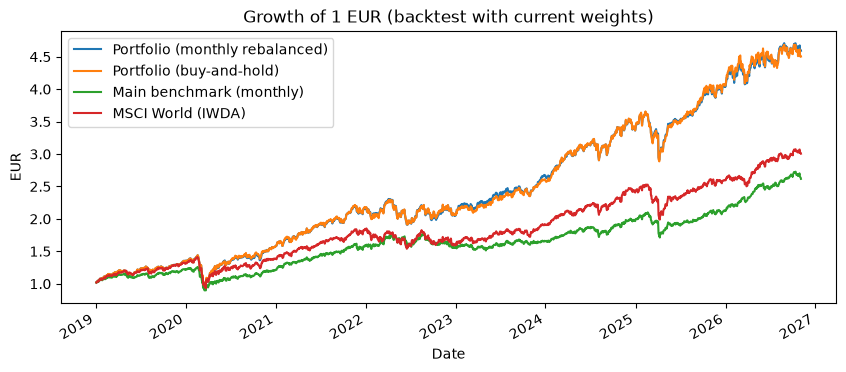

In [6]:
growth = (1 + series.dropna()).cumprod()
ax = growth.plot(figsize=(10, 4), title="Growth of 1 EUR (backtest with current weights)")
ax.set_ylabel("EUR")
plt.show()

## Performance metrics

In [7]:
full = pd.DataFrame({
    name: metrics(series[name], rf, bench=bench_monthly if name.startswith("Portfolio") else None)
    for name in series.columns
}).T
full.round(3)

,start,ann_return,ann_vol,sharpe,sortino,max_drawdown,beta,tracking_error,information_ratio
Portfolio (monthly rebalanced),2019-01-04,0.208909,0.170439,1.131658,1.566141,-0.353229,0.997836,0.099996,0.750513
Portfolio (buy-and-hold),2019-01-04,0.205942,0.172381,1.106591,1.527172,-0.346542,0.99106,0.104519,0.697718
Main benchmark (monthly),2019-01-04,0.127165,0.138322,0.851854,1.16143,-0.286168,NaN,NaN,NaN
MSCI World (IWDA),2019-01-03,0.145754,0.165691,0.835151,1.160399,-0.339692,NaN,NaN,NaN


In [8]:
rows = {}
for label, (start, end) in SUBPERIODS.items():
    window = slice(start, end)
    rows[("Portfolio", label)] = metrics(port_monthly[window], rf, bench=bench_monthly[window])
    rows[("Benchmark", label)] = metrics(bench_monthly[window], rf)

subperiods = pd.DataFrame(rows).T
subperiods.round(3)

,,start,ann_return,ann_vol,sharpe,sortino,max_drawdown,beta,tracking_error,information_ratio
Portfolio,2019-2021,2019-01-04,0.284775,0.196744,1.401275,1.913106,-0.353229,1.074159,0.100701,1.071252
Benchmark,2019-2021,2019-01-04,0.161563,0.157726,1.063969,1.421862,-0.286168,NaN,NaN,NaN
Portfolio,2022,2022-01-03,-0.049346,0.202633,-0.148135,-0.207919,-0.172408,0.975536,0.124129,-0.206256
Benchmark,2022,2022-01-03,-0.017831,0.164231,-0.026881,-0.036975,-0.125525,NaN,NaN,NaN
Portfolio,2023-now,2023-01-02,0.227121,0.13557,1.373111,1.928587,-0.202606,0.891397,0.092154,0.820136
Benchmark,2023-now,2023-01-02,0.141147,0.112383,0.983892,1.379967,-0.18439,NaN,NaN,NaN


**Read with care.** Daily returns of a portfolio spread over US, European and Asian exchanges are not measured at the same moment (asynchronous closes, ECB fixing at 14:15 CET). This mostly biases **beta and correlations** towards zero. In notebook 05 (risk) we therefore also use weekly returns.

## Pies versus their look-through benchmark

Each pie is backtested on its own (monthly rebalanced) and compared with its benchmark from the first date both have data. AI Boom's benchmark (AIQU) only starts in September 2024, so that comparison is short.

In [9]:
pie_rows = {}
pie_series = {}
for pie, blend in PIE_BENCHMARKS.items():
    members = target[pie_of == pie]
    pie_ret = backtest(holding_returns, members, pie_of[members.index], month_ends(dates) + new_data_dates)
    blend_target = pd.Series(blend)
    blend_ret = backtest(returns_total, blend_target, pd.Series("blend", index=blend_target.index), month_ends(dates))
    common = pd.concat([pie_ret, blend_ret], axis=1).dropna().index
    pie_series[pie] = pie_ret
    stats = metrics(pie_ret[common], rf, bench=blend_ret[common])
    stats["bench_ann_return"] = metrics(blend_ret[common], rf)["ann_return"]
    pie_rows[pie] = stats

pie_table = pd.DataFrame(pie_rows).T
pie_table[["start", "ann_return", "bench_ann_return", "ann_vol", "sharpe", "max_drawdown", "beta", "tracking_error", "information_ratio"]].round(3)

,start,ann_return,bench_ann_return,ann_vol,sharpe,max_drawdown,beta,tracking_error,information_ratio
Kwaliteit,2019-01-04,0.175127,0.143604,0.172422,0.955814,-0.312346,0.737811,0.130041,0.219808
Thematisch,2019-01-04,0.177759,0.146758,0.244156,0.745589,-0.428856,1.223327,0.141018,0.303439
AI Boom,2024-09-18,0.375865,0.268368,0.30383,1.129269,-0.36761,0.732472,0.251986,0.384443
Energie,2019-01-04,0.231574,0.15527,0.217026,1.016879,-0.461972,0.628404,0.165047,0.29536
Mijnbouw,2019-01-04,0.215089,0.186857,0.293089,0.772072,-0.36954,0.768476,0.160806,0.067629
Multipolaire Wereldorde,2019-01-04,0.047143,0.09056,0.170559,0.288776,-0.397455,0.760787,0.09621,-0.468324


## Reconciliation with the Archief sheet

The workbook measures returns between month-end dates with closing prices (not total return) and adds a dividend correction: *pie return = weighted price return + dividend yield × duration*. Positions without a price at the start are left out and the pie is renormalised; pies are combined with target weights. The function below repeats that method in Python with the Yahoo data, so that differences come from the **data**, not the method.

In [10]:
def excel_style_return(returns_price, holdings, start, end):
    """Period return per pie and for the portfolio, using the workbook's method."""
    idx = returns_price.index
    t0 = idx[idx <= pd.Timestamp(start)].max()
    t1 = idx[idx <= pd.Timestamp(end)].max()
    window = returns_price.loc[(idx > t0) & (idx <= t1), holdings["ticker"]]
    period = (1 + window.fillna(0)).prod() - 1
    started = returns_price.loc[:t0, holdings["ticker"]].notna().any()
    years = (pd.Timestamp(end) - pd.Timestamp(start)).days / 365.25

    h = holdings.set_index("ticker")
    h = h.assign(period_return=period, started=started)
    h["total"] = h["period_return"] + h["dividend_yield"].fillna(0) * years
    used = h[h["started"]]
    pie_return = (used["total"] * used["weight_in_pie"]).groupby(used["pie"]).sum() / used.groupby("pie")["weight_in_pie"].sum()
    pie_target = holdings.groupby("pie")["weight_in_portfolio"].sum()
    pie_return["Portefeuille"] = (pie_return * pie_target).sum()
    return pie_return

In [11]:
archief_raw = pd.read_excel(DATA_PATH, sheet_name="Archief", header=None)
header_row = archief_raw.index[archief_raw[0] == "Periode"][0]
assert archief_raw.iat[header_row, 3] == "Portefeuille", "Archief layout changed"

PIE_COLUMNS = {}
for col in range(archief_raw.shape[1]):
    label = archief_raw.iat[header_row - 1, col]
    if label in PIE_BENCHMARKS:
        PIE_COLUMNS[label] = col
assert len(PIE_COLUMNS) == 6, f"Expected 6 pie columns, found {list(PIE_COLUMNS)}"

body = archief_raw.iloc[header_row + 1:]
is_period = (
    pd.to_numeric(body[3], errors="coerce").notna()
    & body[3].map(lambda v: not isinstance(v, bool))
    & ~body[0].astype(str).str.startswith("Geannualiseerd")
    & (pd.to_datetime(body[1], errors="coerce") < pd.to_datetime(body[2], errors="coerce"))
)
archief = body[is_period]
print(f"{len(archief)} periods with data:", list(archief[0]))

16 periods with data: ['Cumulatief sinds start', 'Juni 2026', 'Juli 2026', 'Augustus 2026', 'September 2026', 'Oktober 2026', 'Q3 2025', 'Q4 2025', 'Q1 2026', 'Q2 2026', 'Q3 2026', 'H1 2025', 'H2 2025', 'H1 2026', '2024', '2025']


In [12]:
recon_rows = []
for _, row in archief.iterrows():
    python = excel_style_return(returns_price, holdings, row[1], row[2])
    excel = {"Portefeuille": row[3], **{pie: row[col] for pie, col in PIE_COLUMNS.items()}}
    for name, excel_value in excel.items():
        recon_rows.append({
            "period": row[0],
            "begin": pd.Timestamp(row[1]).date(),
            "end": pd.Timestamp(row[2]).date(),
            "series": name,
            "excel": float(excel_value),
            "python": python[name],
        })

recon = pd.DataFrame(recon_rows)
recon["difference"] = recon["python"] - recon["excel"]
recon[recon["series"] == "Portefeuille"].round(4)

,period,begin,end,series,excel,python,difference
0,Cumulatief sinds start,2023-12-29,2026-10-31,Portefeuille,0.6338,0.6506,0.0168
7,Juni 2026,2026-05-29,2026-06-30,Portefeuille,0.0081,-0.0114,-0.0195
14,Juli 2026,2026-06-30,2026-07-31,Portefeuille,-0.0130,-0.0093,0.0037
21,Augustus 2026,2026-07-31,2026-08-31,Portefeuille,0.0595,0.0592,-0.0003
28,September 2026,2026-08-31,2026-09-30,Portefeuille,-0.0223,-0.0227,-0.0004
35,Oktober 2026,2026-09-30,2026-10-31,Portefeuille,0.0070,0.0061,-0.0009
42,Q3 2025,2025-06-30,2025-09-30,Portefeuille,0.0973,0.0945,-0.0028
49,Q4 2025,2025-09-30,2025-12-31,Portefeuille,0.0490,0.0450,-0.0040
56,Q1 2026,2025-12-31,2026-03-31,Portefeuille,0.0433,0.0308,-0.0125
63,Q2 2026,2026-03-31,2026-06-30,Portefeuille,0.0563,0.0753,0.0189


In [13]:
recon.pivot_table(index="series", columns="period", values="difference", sort=False).round(4)

period,Cumulatief sinds start,Juni 2026,Juli 2026,Augustus 2026,September 2026,Oktober 2026,Q3 2025,Q4 2025,Q1 2026,Q2 2026,Q3 2026,H1 2025,H2 2025,H1 2026,2024,2025
series,,,,,,,,,,,,,,,,
Portefeuille,0.0168,-0.0195,0.0037,-0.0003,-0.0004,-0.0009,-0.0028,-0.0040,-0.0125,0.0189,0.0041,0.0060,-0.0057,0.0079,0.0008,0.0058
Kwaliteit,-0.0003,-0.0166,0.0016,0.0012,-0.0005,-0.0010,0.0014,0.0056,-0.0206,0.0144,0.0023,0.0003,0.0065,-0.0081,-0.0077,0.0067
Thematisch,-0.0016,0.0066,-0.0105,0.0136,-0.0101,-0.0000,-0.0193,0.0041,-0.0213,0.0503,-0.0074,-0.0035,-0.0104,0.0241,0.0024,-0.0145
AI Boom,-0.0115,0.0062,-0.0082,-0.0000,0.0000,-0.0046,-0.0000,-0.0272,0.0096,0.0377,-0.0082,-0.0000,-0.0335,0.0641,-0.0000,-0.0335
Energie,0.0114,0.0191,-0.0017,-0.0120,0.0095,-0.0018,-0.0002,-0.0227,0.0331,0.0070,-0.0043,0.0003,-0.0254,0.0367,0.0059,-0.0302
Mijnbouw,0.1055,-0.1102,0.0334,0.0006,-0.0007,-0.0017,0.0003,0.0148,-0.0564,0.0044,0.0404,0.0362,0.0258,-0.0447,0.0084,0.0990
Multipolaire Wereldorde,-0.0115,-0.0078,0.0008,-0.0023,-0.0037,0.0028,-0.0045,-0.0118,-0.0101,0.0183,-0.0057,0.0011,-0.0170,0.0099,0.0006,-0.0147


**Expected sources of difference** (to be confirmed per row):
1. **Price source**: Yahoo versus manually entered Trading212 prices, including different listings (EW on NYSE instead of Xetra, Assa Abloy in Stockholm instead of OTC, HBM on TSX instead of NYSE, alternative lines for several ETFs).
2. **Coverage**: Yahoo has EW before 2024, the workbook does not; the workbook treats a missing price as 0, Python as `NaN`.
3. **Proxies**: EPIN before February 2026 is the US fund EPI in Python and a CFD in the workbook.
4. **Dates**: a weekend month-end (for example 31-10-2026) uses the last trading day in Python.

**Reconciliation per ticker.** Price return per holding between two dates, workbook (Koersdata EUR) versus Python (Yahoo, EUR). A price of 0 in the workbook is treated as missing, not as a price. `effect_on_pie` is the difference times the weight in the pie, so the largest causes of a pie-level difference come first.

In [14]:
excel_raw = pd.read_excel(DATA_PATH, sheet_name="Koersdata (EUR)", header=None)
header_row = excel_raw.index[excel_raw[0] == "Ticker"][0]
excel_prices = pd.read_excel(DATA_PATH, sheet_name="Koersdata (EUR)", header=header_row)
excel_prices = excel_prices[excel_prices["Ticker"].notna()].set_index("Ticker")
date_columns = [c for c in excel_prices.columns if isinstance(c, pd.Timestamp) or hasattr(c, "year")]
excel_prices = excel_prices[date_columns].apply(pd.to_numeric, errors="coerce").replace(0, np.nan)
excel_prices.columns = pd.to_datetime(excel_prices.columns)


def ticker_reconciliation(start, end):
    """Price return per holding between two dates: workbook (Koersdata EUR) versus Python (Yahoo, EUR)."""
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    idx = returns_price.index
    t0 = idx[idx <= start].max()
    t1 = idx[idx <= end].max()
    window = returns_price.loc[(idx > t0) & (idx <= t1), holdings["ticker"]]
    started = returns_price.loc[:t0, holdings["ticker"]].notna().any()
    python = ((1 + window.fillna(0)).prod() - 1).where(started)

    excel = excel_prices[end] / excel_prices[start] - 1
    out = holdings.set_index("ticker")[["pie", "weight_in_pie"]].copy()
    out["excel"] = excel.reindex(out.index)
    out["python"] = python.reindex(out.index)
    out["difference"] = out["python"] - out["excel"]
    out["effect_on_pie"] = out["difference"] * out["weight_in_pie"]
    return out.sort_values("effect_on_pie", key=abs, ascending=False)

In [15]:
recon_june = ticker_reconciliation("2026-05-29", "2026-06-30")
recon_june[recon_june["pie"] == "Mijnbouw"].round(4)

,pie,weight_in_pie,excel,python,difference,effect_on_pie
ticker,,,,,,
GDX,Mijnbouw,0.32,0.0157,-0.1461,-0.1618,-0.0518
HBM,Mijnbouw,0.07,0.2593,-0.1767,-0.4360,-0.0305
SILV,Mijnbouw,0.15,0.0394,-0.1491,-0.1885,-0.0283
FNV,Mijnbouw,0.08,-0.0819,-0.0767,0.0052,0.0004
WREE,Mijnbouw,0.07,-0.1315,-0.1316,-0.0000,-0.0000
WPM,Mijnbouw,0.07,-0.1344,-0.1344,-0.0000,-0.0000
FCX,Mijnbouw,0.08,-0.0219,-0.0219,0.0000,0.0000
NXE,Mijnbouw,0.07,-0.1699,-0.1699,0.0000,0.0000
RIO,Mijnbouw,0.09,-0.1005,-0.1005,-0.0000,-0.0000


In [16]:
mismatch_frames = []
for _, row in archief.iterrows():
    r = ticker_reconciliation(row[1], row[2])
    r = r[r["difference"].abs() > 0.05]
    mismatch_frames.append(r.assign(period=row[0]))

mismatches = pd.concat(mismatch_frames).reset_index()
print(mismatches.groupby("ticker").size().sort_values(ascending=False))
mismatches[["period", "ticker", "pie", "excel", "python", "difference"]].round(3)

ticker
GDX       10
VRT        9
SILV       8
AI         5
NXE        5
TSM        5
ASML       5
CCJ        4
LOCK       4
ASSA B     3
BWXT       3
DAGB       3
VGEK       3
GEV        2
RBOT       2
GRID       2
HBM        1
CSU        1
CEG        1
WENS       1
dtype: int64


,period,ticker,pie,excel,python,difference
0,Cumulatief sinds start,GDX,Mijnbouw,1.297,1.515,0.218
1,Cumulatief sinds start,AI,Energie,0.027,0.243,0.216
2,Cumulatief sinds start,VGEK,Multipolaire Wereldorde,0.774,0.711,-0.063
3,Juni 2026,GDX,Mijnbouw,0.016,-0.146,-0.162
4,Juni 2026,HBM,Mijnbouw,0.259,-0.177,-0.436
...,...,...,...,...,...,...
72,2025,CCJ,Energie,0.696,0.574,-0.122
73,2025,DAGB,Thematisch,0.036,-0.023,-0.060
74,2025,BWXT,Energie,0.443,0.372,-0.072
75,2025,GEV,Energie,0.827,0.757,-0.070


**Reconciliation result and data policy.** Yahoo Finance is the primary price source, with automated quality checks (jump and spike detection) and documented corrections in `price_overrides.csv`. The manually maintained workbook serves as an independent check. Remaining differences fall into three categories: (1) manual input errors in the workbook, of which the largest (GDX, SILV, HBM at 29-05-2026) were confirmed against a third source and corrected in the master workbook after this snapshot; (2) corporate actions that Yahoo adjusts for and manual prices do not, such as Air Liquide's bonus shares; (3) structural differences from a different listing or proxy (HBM in CAD vs USD, Assa Abloy in SEK vs OTC USD, EPIN and LYXI UCITS vs CFD, alternative ETF listings). Category 3 differences are expected and not corrected.

## Real returns

The thesis is about purchasing power, so returns are also shown after euro-area inflation (HICP, monthly index from the ECB). Wealth at each month-end is divided by the price level of that month relative to December 2018. Cash earns €STR. HICP is published with a lag of a few weeks, so the last month(s) may be missing.

In [17]:
hicp_raw = pd.read_csv(HICP_URL)
hicp = hicp_raw.set_index(pd.PeriodIndex(hicp_raw["TIME_PERIOD"], freq="M"))["OBS_VALUE"].sort_index()

monthly_wealth = (1 + series.assign(**{"Cash (€STR)": rf})).cumprod().resample("ME").last()
monthly_wealth.index = monthly_wealth.index.to_period("M")
months = monthly_wealth.index.intersection(hicp.index)
print(f"HICP from {hicp.index.min()} to {hicp.index.max()}; real returns up to {months.max()}")


def real_returns(start_month, end_month):
    """Annualised nominal, inflation and real return between two month-ends."""
    start, end = pd.Period(start_month, "M"), pd.Period(end_month, "M")
    window = [m for m in months if start <= m <= end]
    first, last = window[0], window[-1]
    base_wealth = monthly_wealth.loc[first - 1] if first - 1 in monthly_wealth.index else 1.0
    n_years = (len(window)) / 12
    nominal = monthly_wealth.loc[last] / base_wealth
    inflation = hicp.loc[last] / hicp.loc[first - 1]
    return pd.DataFrame({
        "nominal": nominal ** (1 / n_years) - 1,
        "inflation": inflation ** (1 / n_years) - 1,
        "real": (nominal / inflation) ** (1 / n_years) - 1,
    })

HICP from 2018-12 to 2025-12; real returns up to 2025-12


In [18]:
real_full = real_returns("2019-01", str(months.max()))
real_full.round(4)

,nominal,inflation,real
Portfolio (monthly rebalanced),0.2204,0.0318,0.1828
Portfolio (buy-and-hold),0.2214,0.0318,0.1838
Main benchmark (monthly),0.1134,0.0318,0.0791
MSCI World (IWDA),0.1450,0.0318,0.1097
Cash (€STR),0.0107,0.0318,-0.0204


In [19]:
real_rows = []
for label, (start, end) in SUBPERIODS.items():
    end_month = min(pd.Period(end[:7], "M"), months.max())
    table = real_returns(start[:7], str(end_month)).assign(period=label)
    real_rows.append(table.reset_index(names="series"))

real_sub = pd.concat(real_rows, ignore_index=True)
real_sub.pivot_table(index="series", columns="period", values="real", sort=False).round(4)

period,2019-2021,2022,2023-now
series,,,
Portfolio (monthly rebalanced),0.2677,-0.1305,0.2228
Portfolio (buy-and-hold),0.2694,-0.1308,0.2237
Main benchmark (monthly),0.1432,-0.1009,0.0825
MSCI World (IWDA),0.1982,-0.2037,0.1480
Cash (€STR),-0.0250,-0.0843,0.0065


## Export

In [20]:
backtest_long = series.stack().dropna().rename("return").reset_index()
backtest_long.columns = ["date", "series", "return"]

pie_long = pd.DataFrame(pie_series).stack().dropna().rename("return").reset_index()
pie_long.columns = ["date", "pie", "return"]

with sqlite3.connect(DB_PATH) as con:
    backtest_long.to_sql("backtest_returns", con, if_exists="replace", index=False)
    pie_long.to_sql("pie_returns", con, if_exists="replace", index=False)
    full.reset_index(names="series").astype(str).to_sql("performance_full", con, if_exists="replace", index=False)
    real_full.reset_index(names="series").to_sql("real_returns", con, if_exists="replace", index=False)

series.to_parquet(PROCESSED_DIR / "backtest_returns.parquet")
pd.DataFrame(pie_series).to_parquet(PROCESSED_DIR / "pie_returns.parquet")
recon.to_parquet(PROCESSED_DIR / "archief_reconciliation.parquet")
real_full.reset_index(names="series").to_parquet(PROCESSED_DIR / "real_returns.parquet", index=False)
"exported"

'exported'